In [23]:
file=r"C:\Users\Sneha\Downloads\sales_data_sample.csv"



In [24]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
import matplotlib as mlt;


In [25]:
df = pd.read_csv(file, encoding='latin1')
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,Motorcycles,95,S10_1678,Corporate Gift Ideas Co.,6505551386,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [26]:
df.columns

Index(['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER',
       'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID',
       'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE',
       'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE',
       'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME',
       'DEALSIZE'],
      dtype='str')

In [27]:
df.drop(["ORDERNUMBER","ORDERLINENUMBER"],axis=1,inplace=True)

In [28]:
df.isnull().sum()


QUANTITYORDERED        0
PRICEEACH              0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [29]:
df.fillna(df.median)

,QUANTITYORDERED,PRICEEACH,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,30,95.70,2871.00,2/24/2003 0:00,Shipped,1,2,2003,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,<bound method DataFrame.median of QUANTI...,NYC,NY,10022,USA,<bound method DataFrame.median of QUANTI...,Yu,Kwai,Small
1,34,81.35,2765.90,5/7/2003 0:00,Shipped,2,5,2003,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,<bound method DataFrame.median of QUANTI...,Reims,<bound method DataFrame.median of QUANTI...,51100,France,EMEA,Henriot,Paul,Small
2,41,94.74,3884.34,7/1/2003 0:00,Shipped,3,7,2003,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,<bound method DataFrame.median of QUANTI...,Paris,<bound method DataFrame.median of QUANTI...,75508,France,EMEA,Da Cunha,Daniel,Medium
3,45,83.26,3746.70,8/25/2003 0:00,Shipped,3,8,2003,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,<bound method DataFrame.median of QUANTI...,Pasadena,CA,90003,USA,<bound method DataFrame.median of QUANTI...,Young,Julie,Medium
4,49,100.00,5205.27,10/10/2003 0:00,Shipped,4,10,2003,Motorcycles,95,S10_1678,Corporate Gift Ideas Co.,6505551386,7734 Strong St.,<bound method DataFrame.median of QUANTI...,San Francisco,CA,<bound method DataFrame.median of QUANTI...,USA,<bound method DataFrame.median of QUANTI...,Brown,Julie,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2818,20,100.00,2244.40,12/2/2004 0:00,Shipped,4,12,2004,Ships,54,S72_3212,Euro Shopping Channel,(91) 555 94 44,"C/ Moralzarzal, 86",<bound method DataFrame.median of QUANTI...,Madrid,<bound method DataFrame.median of QUANTI...,28034,Spain,EMEA,Freyre,Diego,Small
2819,29,100.00,3978.51,1/31/2005 0:00,Shipped,1,1,2005,Ships,54,S72_3212,"Oulu Toy Supplies, Inc.",981-443655,Torikatu 38,<bound method DataFrame.median of QUANTI...,Oulu,<bound method DataFrame.median of QUANTI...,90110,Finland,EMEA,Koskitalo,Pirkko,Medium
2820,43,100.00,5417.57,3/1/2005 0:00,Resolved,1,3,2005,Ships,54,S72_3212,Euro Shopping Channel,(91) 555 94 44,"C/ Moralzarzal, 86",<bound method DataFrame.median of QUANTI...,Madrid,<bound method DataFrame.median of QUANTI...,28034,Spain,EMEA,Freyre,Diego,Medium
2821,34,62.24,2116.16,3/28/2005 0:00,Shipped,1,3,2005,Ships,54,S72_3212,Alpha Cognac,61.77.6555,1 rue Alsace-Lorraine,<bound method DataFrame.median of QUANTI...,Toulouse,<bound method DataFrame.median of QUANTI...,31000,France,EMEA,Roulet,Annette,Small


In [36]:
df.head()

,QUANTITYORDERED,PRICEEACH,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,30,95.70,2871.00,2/24/2003 0:00,Shipped,1,2,2003,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,NaN,Yu,Kwai,Small
1,34,81.35,2765.90,5/7/2003 0:00,Shipped,2,5,2003,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,EMEA,Henriot,Paul,Small
2,41,94.74,3884.34,7/1/2003 0:00,Shipped,3,7,2003,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,EMEA,Da Cunha,Daniel,Medium
3,45,83.26,3746.70,8/25/2003 0:00,Shipped,3,8,2003,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,NaN,Young,Julie,Medium
4,49,100.00,5205.27,10/10/2003 0:00,Shipped,4,10,2003,Motorcycles,95,S10_1678,Corporate Gift Ideas Co.,6505551386,7734 Strong St.,San Francisco,NaN,USA,NaN,Brown,Julie,Medium


In [37]:
df.drop("TERRITORY",axis=1,inplace=True)

In [30]:
df.drop("ADDRESSLINE2",axis=1,inplace=True)

In [31]:
df.shape

(2823, 22)

In [39]:
df.isnull().sum()

QUANTITYORDERED     0
PRICEEACH           0
SALES               0
ORDERDATE           0
STATUS              0
QTR_ID              0
MONTH_ID            0
YEAR_ID             0
PRODUCTLINE         0
MSRP                0
PRODUCTCODE         0
CUSTOMERNAME        0
PHONE               0
ADDRESSLINE1        0
CITY                0
COUNTRY             0
CONTACTLASTNAME     0
CONTACTFIRSTNAME    0
DEALSIZE            0
dtype: int64

In [41]:
df.describe()

,QUANTITYORDERED,PRICEEACH,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.00000,2823.000000
mean,35.092809,83.658544,3553.889072,2.717676,7.092455,2003.81509,100.715551
std,9.741443,20.174277,1841.865106,1.203878,3.656633,0.69967,40.187912
min,6.000000,26.880000,482.130000,1.000000,1.000000,2003.00000,33.000000
25%,27.000000,68.860000,2203.430000,2.000000,4.000000,2003.00000,68.000000
50%,35.000000,95.700000,3184.800000,3.000000,8.000000,2004.00000,99.000000
75%,43.000000,100.000000,4508.000000,4.000000,11.000000,2004.00000,124.000000
max,97.000000,100.000000,14082.800000,4.000000,12.000000,2005.00000,214.000000


In [42]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   QUANTITYORDERED   2823 non-null   int64  
 1   PRICEEACH         2823 non-null   float64
 2   SALES             2823 non-null   float64
 3   ORDERDATE         2823 non-null   str    
 4   STATUS            2823 non-null   str    
 5   QTR_ID            2823 non-null   int64  
 6   MONTH_ID          2823 non-null   int64  
 7   YEAR_ID           2823 non-null   int64  
 8   PRODUCTLINE       2823 non-null   str    
 9   MSRP              2823 non-null   int64  
 10  PRODUCTCODE       2823 non-null   str    
 11  CUSTOMERNAME      2823 non-null   str    
 12  PHONE             2823 non-null   str    
 13  ADDRESSLINE1      2823 non-null   str    
 14  CITY              2823 non-null   str    
 15  COUNTRY           2823 non-null   str    
 16  CONTACTLASTNAME   2823 non-null   str    
 17  CONTAC

In [62]:
df.head()

,QUANTITYORDERED,PRICEEACH,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE,cluster
0,30,95.70,2871.00,2/24/2003 0:00,Shipped,1,2,2003,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,USA,Yu,Kwai,Small,2
1,34,81.35,2765.90,5/7/2003 0:00,Shipped,2,5,2003,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,France,Henriot,Paul,Small,1
2,41,94.74,3884.34,7/1/2003 0:00,Shipped,3,7,2003,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,France,Da Cunha,Daniel,Medium,0
3,45,83.26,3746.70,8/25/2003 0:00,Shipped,3,8,2003,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,USA,Young,Julie,Medium,0
4,49,100.00,5205.27,10/10/2003 0:00,Shipped,4,10,2003,Motorcycles,95,S10_1678,Corporate Gift Ideas Co.,6505551386,7734 Strong St.,San Francisco,USA,Brown,Julie,Medium,0


In [38]:
df.drop("POSTALCODE",axis=1,inplace=True)

In [34]:
df.drop("STATE",axis=1,inplace=True)

In [ ]:
x=df[""]

In [43]:
x=df.select_dtypes(include=['int64','float64'])

AttributeError: 'numpy.ndarray' object has no attribute 'head'

In [45]:
sc=StandardScaler()

x=sc.fit_transform(x)



In [56]:
wcss=[]
for k in range (1,6):
    model=KMeans(n_clusters=k,random_state=42, n_init=10)
    model.fit(x)
    wcss.append(model.inertia_)


In [53]:
print(wcss)

[19761.0, 14564.928586859573, 11567.18025128251, 9987.08334724544, 8857.599200203222, 8003.942886044377, 7445.840353865475, 6965.687412197025, 6640.725203290071, 6306.560014940959, 5995.053687035507, 5738.196285027825, 5534.8018838812495, 5299.460419669709, 5128.180461900705, 4971.738732958393, 4774.468567331651, 4638.455150056626, 4519.195977592215, 4380.539559296387]


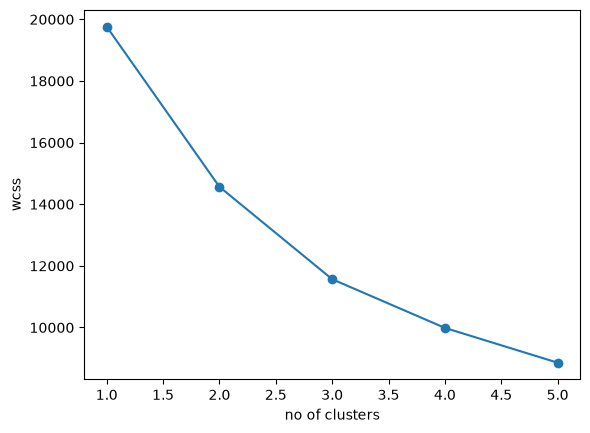

In [57]:
import matplotlib.pyplot as plt
plt.plot(range(1,6),wcss, marker='o')
plt.xlabel("no of clusters")
plt.ylabel("wcss")
plt.show()

In [58]:
k=3

model=KMeans(n_clusters=k,random_state=42,n_init=10)

df["cluster"]=model.fit_predict(x)

In [59]:
df["cluster"].value_counts()

cluster
0    1043
2     930
1     850
Name: count, dtype: int64

In [61]:
print(model.cluster_centers_)

[[ 0.04323464  0.68147538  0.50912051  0.73876623  0.73181966 -0.42369504
   0.57987381]
 [-0.18395119 -1.14593238 -0.84806939  0.33229419  0.33737209 -0.28560831
  -0.916511  ]
 [ 0.11963956  0.28307925  0.20413579 -1.13224003 -1.12909053  0.73621611
   0.18733975]]
